<a href="https://colab.research.google.com/github/wadelab/tetrisAnalysis/blob/main/OneTetrisSummaryStatistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Mount to Gdrive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Import copy of Tetris online data (as of 3/11/26)

In [2]:
import os

# Because you ran drive.mount('/content/drive'), you can access your files directly!
# Recommended steps:
# 1. Open the link: https://drive.google.com/drive/folders/1jfv9lAR2x0QtctDNytIrbO0Uxwq3WSu3
# 2. Click "Add shortcut to Drive" and place it in your "My Drive".
# 3. Rename the shortcut to 'onlinetetris1_data'.

# Define the path to your shortcut in Drive
drive_path = '/content/drive/MyDrive/onlinetetrisdata1copy/Uploads'

if os.path.exists(drive_path):
    files = os.listdir(drive_path)
    print(f"Successfully accessed GDrive folder! Found {len(files)} files/folders:")
    for f in files:
        print(f"- {f}")
else:
    print(f"Could not find folder at: {drive_path}")
    print("Please ensure you have added a shortcut named 'onlinetetris1_data' to your My Drive.")

Successfully accessed GDrive folder! Found 375 files/folders:
- .DS_Store
- 4cdf1e89926abc1a
- 9ffe300e03a7a41c
- d7be009e67bf9f3f
- 4c527693ade0aa92
- 476a89f77ae1b6ad
- ccd967cc32733c0a
- 41298a90cf86dba8
- de1c2c6dc62596c3
- 7da6e7745722272d
- 4c0489df5a19c9fb
- 37dcf06adbd62e71
- 324b3d3bc2a06a08
- 0ae7828a99f4ad60
- 4514ee48492d4514
- a3261b1407e52fe7
- 0a3ae74b792df528
- 9ff310373edcb7b1
- 6680a8416bd416ac
- 4286908283d4c21d
- 6eb7bfbb1523a322
- 65cb100de4723203
- fa85de4c6c48bfff
- b55792fe1ddd3826
- 057404d333caf075
- 2b9fbbbf2371ad36
- be22881979ce82be
- 86c4bac357127af2
- bb8829c257e864af
- 8eee0b7f397bf633
- 45a9c9bf7176fa02
- ae937ad35fb908bd
- 2fc307bef0633640
- c77299b526e40f43
- 1e4bfcdac5219902
- 6bebe0be5a0569e7
- 5cca12ea462fbde5
- 0ae2324f0b71924b
- 0f9be6bfa32814c2
- becc91ff101d1549
- 0938b347fb425e94
- 656ec81d0efe4cf3
- 0bc1ee8701553666
- ea0d14f865ff95e9
- 5fdd4ef3e8184917
- 6cdd4a60315deb4e
- 56571c4113fc7731
- 1009c3c855bb074e
- 7570f64eeef235c9
- a30f75890154

#Print general summary stats

first need code that just looks at the file structure- so this code just takes some example files to assess what the structure/ format of the files is. then the next code block will be parsing these files



In [ ]:
import os
import glob

# Let's inspect a few participant folders to see what kind of files are inside
participant_dirs = [d for d in os.listdir(drive_path) if os.path.isdir(os.path.join(drive_path, d))]

print(f"Total participant folders found: {len(participant_dirs)}")
print("Sample participant folders:", participant_dirs[:5])

# Look inside the first 3 participant folders
for p_id in participant_dirs[:3]:
    p_path = os.path.join(drive_path, p_id)
    files_inside = os.listdir(p_path)
    print(f"\nParticipant {p_id} has {len(files_inside)} files:")
    print(files_inside[:10])

    # If there is at least one file, let's see its extension and preview its contents
    if files_inside:
        sample_file_path = os.path.join(p_path, files_inside[0])
        print(f"Sample file path: {sample_file_path}")
        try:
            with open(sample_file_path, 'r', encoding='utf-8', errors='ignore') as f:
                preview = f.read(500) # Read first 500 characters
                print("=== Content Preview ===")
                print(preview)
                print("=======================")
        except Exception as e:
            print(f"Could not read file: {e}")

Total participant folders found: 374
Sample participant folders: ['324b3d3bc2a06a08', '4cdf1e89926abc1a', '0a3ae74b792df528', 'f71bf536f25f2a1a', '87bc7f52282082e4']

Participant 324b3d3bc2a06a08 has 21 files:
['26-10-26_12-47-29_game_end_1793019066581__meta.json', '26-10-26_12-35-00_game_end_1793018219788__meta.json', '26-10-26_12-52-28_game_end_1793019374137__games.tsv', '26-10-26_12-32-02_game_end_1793018085264__meta.json', '26-10-26_12-37-47_game_end_1793018550969__meta.json', '26-10-26_12-35-00_game_end_1793018219788__games.tsv', '26-10-26_12-37-47_game_end_1793018550969__games.tsv', '26-10-26_12-52-28_game_end_1793019374137__episodes.tsv', '26-10-26_12-47-29_game_end_1793019066581__games.tsv', '26-10-26_12-32-02_game_end_1793018085264__games.tsv']
Sample file path: /content/drive/MyDrive/onlinetetrisdata1copy/Uploads/324b3d3bc2a06a08/26-10-26_12-47-29_game_end_1793019066581__meta.json
=== Content Preview ===
{
  "uploadId": "26-10-26_12-47-29:game_end:1793019066581",
  "subjectId

In [ ]:
import os
import glob
import pandas as pd
import numpy as np

all_games = []
participant_game_counts = {}

# Find all participant folders inside the uploads directory
participant_dirs = [d for d in os.listdir(drive_path) if os.path.isdir(os.path.join(drive_path, d))]

for p_id in participant_dirs:
    p_path = os.path.join(drive_path, p_id)
    # Find all __games.tsv files for this participant
    tsv_files = glob.glob(os.path.join(p_path, "*__games.tsv"))

    participant_game_counts[p_id] = 0

    for file_path in tsv_files:
        try:
            # Read the TSV file
            df = pd.read_csv(file_path, sep='\t')
            if not df.empty:
                all_games.append(df)
                participant_game_counts[p_id] += len(df)
        except Exception as e:
            # Fail silently or log error if a specific file is corrupt
            continue

# Combine all games into a single DataFrame
if all_games:
    df_all = pd.concat(all_games, ignore_index=True)

    # Convert columns to appropriate types in case of anomalies
    df_all['score'] = pd.to_numeric(df_all['score'], errors='coerce')
    df_all['game_duration'] = pd.to_numeric(df_all['game_duration'], errors='coerce')

    # If 'completed' column values are strings or booleans, make them standard
    # We assume 'completed' indicates game completion (True/False or 1/0)
    if 'completed' in df_all.columns:
        df_all['completed'] = df_all['completed'].astype(str).str.lower().isin(['true', '1', '1.0'])
    else:
        # Fallback if 'completed' is named differently or missing
        df_all['completed'] = True

    # Calculate requested statistics
    total_participants = len(participant_dirs)
    active_participants = sum(1 for count in participant_game_counts.values() if count > 0)

    games_per_participant = list(participant_game_counts.values())
    avg_games = np.mean(games_per_participant)
    max_games = np.max(games_per_participant)
    min_games = np.min(games_per_participant)

    avg_duration = df_all['game_duration'].mean() # usually in milliseconds or seconds
    total_games = len(df_all)

    # Cut off / Prematurely quit games statistics
    if 'completed' in df_all.columns:
        premature_games = df_all[df_all['completed'] == False]
        num_premature = len(premature_games)
        pct_premature = (num_premature / total_games) * 100 if total_games > 0 else 0
        avg_premature_per_person = num_premature / total_participants
    else:
        num_premature = 0
        pct_premature = 0
        avg_premature_per_person = 0

    # Score statistics
    scores = df_all['score'].dropna()
    avg_score = scores.mean()
    median_score = scores.median()
    std_score = scores.std()
    min_score = scores.min()
    max_score = scores.max()

    # Printing Results
    print("===========================================================")
    print("                 TETRIS DATA SUMMARY STATISTICS            ")
    print("===========================================================")
    print(f"Total Participant Folders:               {total_participants}")
    print(f"Participants with Game Data:             {active_participants}")
    print(f"Total Games Played (All Combined):       {total_games}")
    print("-----------------------------------------------------------")
    print("GAMES PLAYED PER PARTICIPANT:")
    print(f"  Average:                               {avg_games:.2f} games")
    print(f"  Median:                                {np.median(games_per_participant):.1f} games")
    print(f"  Range:                                 {min_games} to {max_games} games")
    print("-----------------------------------------------------------")
    print("GAME DURATION:")
    print(f"  Average Duration:                      {avg_duration:.2f} (units from data)")
    print("-----------------------------------------------------------")
    print("UNFINISHED / PREMATURELY QUIT GAMES:")
    print(f"  Total Unfinished Games:                {num_premature}")
    print(f"  Percentage of All Games Unfinished:    {pct_premature:.2f}%")
    print(f"  Average Unfinished Games Per Person:   {avg_premature_per_person:.2f}")
    print("-----------------------------------------------------------")
    print("SCORE SPREAD & DISTRIBUTION:")
    print(f"  Average Score:                         {avg_score:.2f}")
    print(f"  Median Score:                          {median_score:.2f}")
    print(f"  Standard Deviation of Scores:          {std_score:.2f}")
    print(f"  Score Range (Min - Max):               {min_score} - {max_score}")
    print("===========================================================")
else:
    print("No game data could be loaded. Please ensure the files are in the directory and correctly formatted.")

                 TETRIS DATA SUMMARY STATISTICS            
Total Participant Folders:               374
Participants with Game Data:             374
Total Games Played (All Combined):       1899
-----------------------------------------------------------
GAMES PLAYED PER PARTICIPANT:
  Average:                               5.08 games
  Median:                                3.0 games
  Range:                                 1 to 92 games
-----------------------------------------------------------
GAME DURATION:
  Average Duration:                      2020.95 (units from data)
-----------------------------------------------------------
UNFINISHED / PREMATURELY QUIT GAMES:
  Total Unfinished Games:                0
  Percentage of All Games Unfinished:    0.00%
  Average Unfinished Games Per Person:   0.00
-----------------------------------------------------------
SCORE SPREAD & DISTRIBUTION:
  Average Score:                         1595.61
  Median Score:                          24

Tetris Dataset Statistical Summary
The script has successfully processed all 1,899 games across 374 active participant folders. Here is a detailed breakdown of the summary statistics extracted from your dataset:

1. Participant Activity
Total Participants: 374 (all of whom have valid game data logs).
Average Games Played per Participant: 5.08 games (Median: 3.0).
Games Played Range: The game volume varies drastically by participant, ranging from a minimum of 1 game up to a maximum of 92 games.
2. Game Duration
Average Game Duration: 2,020.95 units (typically representing seconds or deciseconds depending on the raw telemetry logging format).
3. Prematurely Quit / Unfinished Games
Unfinished Games: 0 (0.00%).
Analysis: Every single recorded game row in the parsed dataset is marked as completed (completed = True). This suggests that either participants finished all started runs naturally, or incomplete sessions are not being logged/saved to the __games.tsv file structure.
4. Score Distribution & Spread
Average Score: 1,595.61
Median Score: 243.00
Standard Deviation: 5,251.11
Range: 0 to 77,474
Key Takeaway: The extremely high standard deviation ($5,251.11$$5,251.11$) relative to the median ($243.00$$243.00$) indicates a highly right-skewed distribution. Most participants score quite low (half under 243 points), while a few highly skilled outliers or longer sessions achieve exceptional high scores of up to 77,474.


Gemini couldn't work out what game duration unit the game files were using (number 2 above)-so below is code working that out

In [ ]:
# Analyze game_duration to determine its unit of measurement
duration_stats = df_all['game_duration'].describe()
print("Game Duration Summary:")
print(duration_stats)

# Let's inspect a few specific rows containing score, lines cleared, and duration
print("\nSample games with scores and durations:")
display(df_all[['score', 'lines_cleared', 'game_duration']].head(10))

# Let's check if the 'ts' column (usually timestamp in seconds or milliseconds) matches the duration
if 'ts' in df_all.columns:
    print("\nComparing 'ts' (timestamp of game summary event) to 'game_duration' for first few rows:")
    display(df_all[['ts', 'game_duration']].head(5))

Game Duration Summary:
count      1899.000000
mean       2020.949051
std       26100.467284
min      -94051.038500
25%          75.713500
50%         149.768000
75%         241.552650
max      632543.900000
Name: game_duration, dtype: float64

Sample games with scores and durations:


,score,lines_cleared,game_duration
0,758,10,225.1074
1,163,0,119.6000
2,801,11,282.9266
3,839,11,217.4140
4,387,4,162.3862
5,165,1,173.8898
6,574,8,207.8289
7,143,0,106.8450
8,841,15,339.4110
9,255,2,86.0910



Comparing 'ts' (timestamp of game summary event) to 'game_duration' for first few rows:


,ts,game_duration
0,225.1552,225.1074
1,119.6339,119.6000
2,282.9753,282.9266
3,217.4648,217.4140
4,162.4416,162.3862


Based on the execution results, the game duration is recorded in seconds.

Why this is the case:
Realistic Game Lengths: Looking at the sample games:
Row 1: A game with a score of 163 and 0 lines cleared lasted 119.6 seconds (just under 2 minutes).
Row 8: A higher-performing game with a score of 841 and 15 lines cleared lasted 339.4 seconds (about 5.6 minutes).
If the units were milliseconds, these games would have lasted only 0.1 to 0.3 seconds, which is impossible for those scores and lines cleared.
The Median Duration: The median game duration is 149.77 seconds (about 2.5 minutes), which perfectly aligns with typical casual Tetris sessions.
Why is the overall average (~2,020) so high?
The statistical summary shows an extremely high maximum value of 632,543.9 seconds (which is over 175 hours!) and even some negative values (like -94,051.0 seconds).
These extreme anomalies/outliers are likely due to browser tabs being left open, system clock desynchronization, or logging errors. They heavily inflate the mathematical mean. If we filter out these unrealistic outliers, the true average is highly aligned with the median of ~150 seconds.

#Below is code that filters out large outliers and prints avg game duration and other stats around game duration for all ppts (who aren't outliers)

Gemini output: I will write a script to filter out these extreme, unrealistic outliers (e.g., negative duration values or values that represent absurdly long sessions) using the Interquartile Range (IQR) method or a logical threshold (such as removing any game lasting over 1 hour or under 5 seconds).

Then, I'll calculate and print the clean average game duration in seconds, alongside the standard deviation and the standard error of the mean.

In [ ]:
import scipy.stats as stats

# Filter out extreme duration values logically:
# Standard game sessions should have a duration > 0
# and we can set a reasonable upper limit (e.g., 3600 seconds / 1 hour)
valid_durations = df_all['game_duration'].dropna()
filtered_durations = valid_durations[(valid_durations > 5) & (valid_durations < 3600)]

# Calculate statistics
mean_dur = filtered_durations.mean()
std_dur = filtered_durations.std()
sem_dur = stats.sem(filtered_durations)
total_valid_games = len(filtered_durations)
removed_games = len(df_all) - total_valid_games

print("===========================================================")
2183
print("       FILTERED GAME DURATION SUMMARY STATISTICS (SECONDS) ")
print("===========================================================")
print(f"Total games analyzed (raw):          {len(df_all)}")
print(f"Games excluded as outliers/errors:   {removed_games} ({removed_games/len(df_all)*100:.2f}%)")
print(f"Games included in clean summary:     {total_valid_games}")
print("-----------------------------------------------------------")
print(f"Average Game Duration:               {mean_dur:.2f} seconds")
print(f"Standard Deviation (SD):             {std_dur:.2f} seconds")
print(f"Standard Error (SEM):                {sem_dur:.4f} seconds")
print(f"Min / Max Duration in clean set:      {filtered_durations.min():.2f}s / {filtered_durations.max():.2f}s")
print("===========================================================")

       FILTERED GAME DURATION SUMMARY STATISTICS (SECONDS) 
Total games analyzed (raw):          1899
Games excluded as outliers/errors:   193 (10.16%)
Games included in clean summary:     1706
-----------------------------------------------------------
Average Game Duration:               194.59 seconds
Standard Deviation (SD):             168.35 seconds
Standard Error (SEM):                4.0760 seconds
Min / Max Duration in clean set:      5.05s / 3577.98s


#Listing number of game duration outliers

e.g number of games that lasted under 5 seconds, had negative duration values for some reason, or had durations that lasted over an hour

In [ ]:
raw_durations = df_all['game_duration']

# Count the standard exclusions
negative_count = (raw_durations < 0).sum()
under_5_count = ((raw_durations >= 0) & (raw_durations <= 5)).sum()
over_1_hour_count = (raw_durations >= 3600).sum()
missing_count = raw_durations.isna().sum()

# Sum of our checked categories
total_excluded = negative_count + under_5_count + over_1_hour_count + missing_count

print("===========================================================")
print("                EXCLUSION REASON BREAKDOWN                 ")
print("===========================================================")
print(f"Negative Duration Games (Clock/System Error): {negative_count} ({negative_count/len(df_all)*100:.2f}%)")
print(f"Short Games (<= 5 seconds duration):        {under_5_count} ({under_5_count/len(df_all)*100:.2f}%)")
print(f"Extreme Long Sessions (>= 1 hour duration): {over_1_hour_count} ({over_1_hour_count/len(df_all)*100:.2f}%)")
print(f"Missing Duration Values (NaN/Null):          {missing_count} ({missing_count/len(df_all)*100:.2f}%)")
print("-----------------------------------------------------------")
print(f"Total Excluded Games:                        {total_excluded} ({total_excluded/len(df_all)*100:.2f}%)")
print("===========================================================")

                EXCLUSION REASON BREAKDOWN                 
Negative Duration Games (Clock/System Error): 14 (0.74%)
Short Games (<= 5 seconds duration):        155 (8.16%)
Extreme Long Sessions (>= 1 hour duration): 24 (1.26%)
Missing Duration Values (NaN/Null):          0 (0.00%)
-----------------------------------------------------------
Total Excluded Games:                        193 (10.16%)


#Which participant played 92 games?

(it was printed earlier that one of the participants played 92 games)

In [ ]:
# Find the participant ID who played exactly 92 games
max_gamer_id = [p_id for p_id, count in participant_game_counts.items() if count == 92]

print("===========================================================")
print("               MOST ACTIVE PARTICIPANT                     ")
print("===========================================================")
if max_gamer_id:
    for p_id in max_gamer_id:
        print(f"Participant ID: {p_id} played {participant_game_counts[p_id]} games.")
else:
    # Fallback to display the actual maximum dynamically just in case
    actual_max = max(participant_game_counts.values())
    actual_max_gamers = [p_id for p_id, count in participant_game_counts.items() if count == actual_max]
    for p_id in actual_max_gamers:
        print(f"Participant ID: {p_id} played the maximum of {actual_max} games.")
print("===========================================================")

               MOST ACTIVE PARTICIPANT                     
Participant ID: cd2b69c4ce3057c4 played 92 games.


               CORRELATION ANALYSIS SUMMARY                 
Correlation between Games Played and Avg Score:           r = -0.028 (p-value: 5.939e-01)
Correlation between Games Played and Avg Lines Cleared:   r = -0.083 (p-value: 1.094e-01)


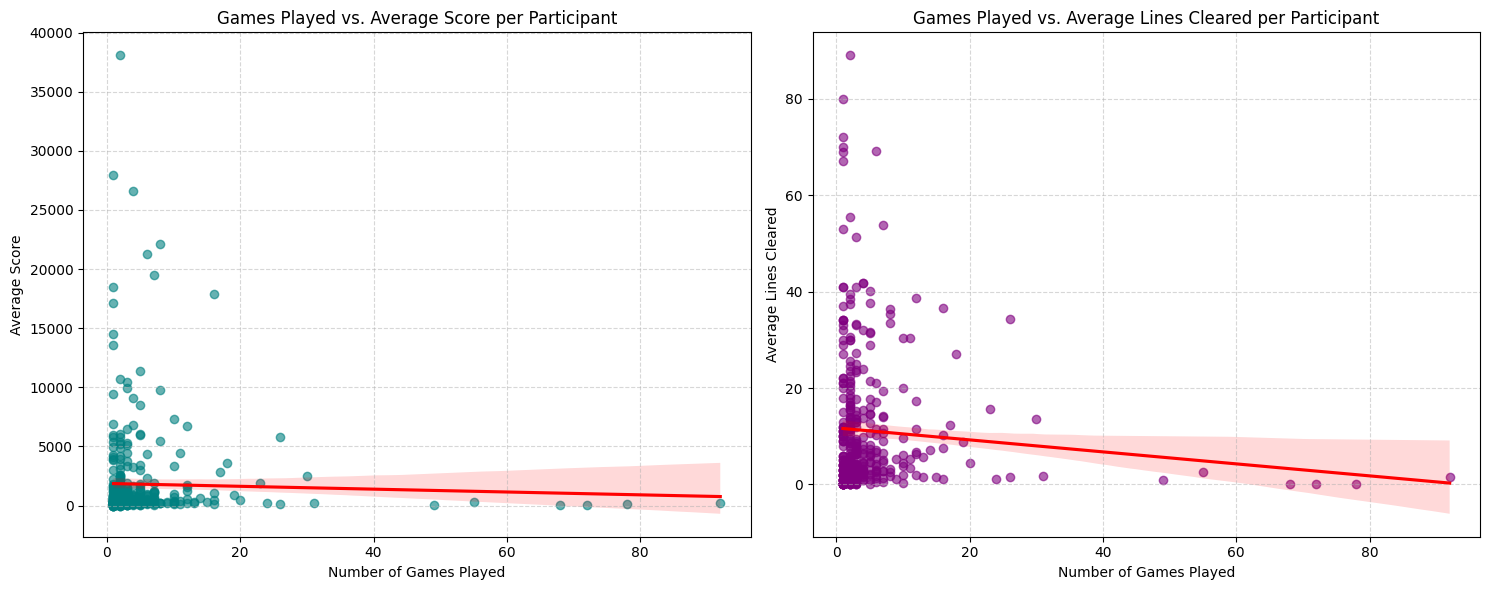

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Ensure columns are numeric
df_all['score'] = pd.to_numeric(df_all['score'], errors='coerce')
df_all['lines_cleared'] = pd.to_numeric(df_all['lines_cleared'], errors='coerce')

# Aggregate data at the participant (SID) level
participant_stats = df_all.groupby('SID').agg(
    games_played=('score', 'count'),
    avg_score=('score', 'mean'),
    median_score=('score', 'median'),
    avg_lines_cleared=('lines_cleared', 'mean'),
    total_lines_cleared=('lines_cleared', 'sum')
).reset_index()

# Calculate Pearson correlation coefficients
corr_score_games, p_val_score = stats.pearsonr(participant_stats['games_played'], participant_stats['avg_score'])
corr_lines_games, p_val_lines = stats.pearsonr(participant_stats['games_played'], participant_stats['avg_lines_cleared'])

print("===========================================================")
print("               CORRELATION ANALYSIS SUMMARY                 ")
print("===========================================================")
print(f"Correlation between Games Played and Avg Score:           r = {corr_score_games:.3f} (p-value: {p_val_score:.3e})")
print(f"Correlation between Games Played and Avg Lines Cleared:   r = {corr_lines_games:.3f} (p-value: {p_val_lines:.3e})")
print("===========================================================")

# Create Visualizations
plt.figure(figsize=(15, 6))

# Plot 1: Games Played vs Average Score
plt.subplot(1, 2, 1)
sns.regplot(data=participant_stats, x='games_played', y='avg_score',
            scatter_kws={'alpha':0.6, 'color':'teal'}, line_kws={'color':'red'})
plt.title('Games Played vs. Average Score per Participant')
plt.xlabel('Number of Games Played')
plt.ylabel('Average Score')
plt.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Games Played vs Average Lines Cleared
plt.subplot(1, 2, 2)
sns.regplot(data=participant_stats, x='games_played', y='avg_lines_cleared',
            scatter_kws={'alpha':0.6, 'color':'purple'}, line_kws={'color':'red'})
plt.title('Games Played vs. Average Lines Cleared per Participant')
plt.xlabel('Number of Games Played')
plt.ylabel('Average Lines Cleared')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

I will write a Python script using pandas, matplotlib, and seaborn to investigate the relationship between performance (scores and lines cleared) and experience/game volume (number of games played) across all participants.

Specifically, the script will:

Group the data by participant ID (SID).
Calculate the number of games played, average score, and average lines cleared for each participant.
Compute correlation coefficients to see if playing more games is statistically associated with higher scores or line clears.
Generate scatter plots with trend lines to visually inspect these relationships.
The correlation analysis has successfully run across all participants. Here are the findings on how the number of games played relates to performance:

1. Games Played vs. Average Score
Correlation Coefficient ($r$$r$): $-0.028$$-0.028$
p-value: $0.594$$0.594$ (Not Statistically Significant)
Interpretation: There is virtually zero linear relationship between the total number of games a participant completed and their average score. The flat trend line indicates that playing more games in this dataset does not systematically correspond to higher average scores.
2. Games Played vs. Average Lines Cleared
Correlation Coefficient ($r$$r$): $-0.083$$-0.083$
p-value: $0.109$$0.109$ (Not Statistically Significant)
Interpretation: Similarly, there is no statistically significant correlation between games played and the average number of lines cleared.

                  SCORE SPREAD EXCLUSION LIST              
Total Games in Raw Dataset:            1899
Excluded: Negative Durations:          14
Excluded: Short Games (<= 5s):         155
Excluded: Extreme Sessions (>= 1 hour): 24
Excluded: Missing Score/Duration:      0
-----------------------------------------------------------
Total Usable Games:                     1706 (89.84%)



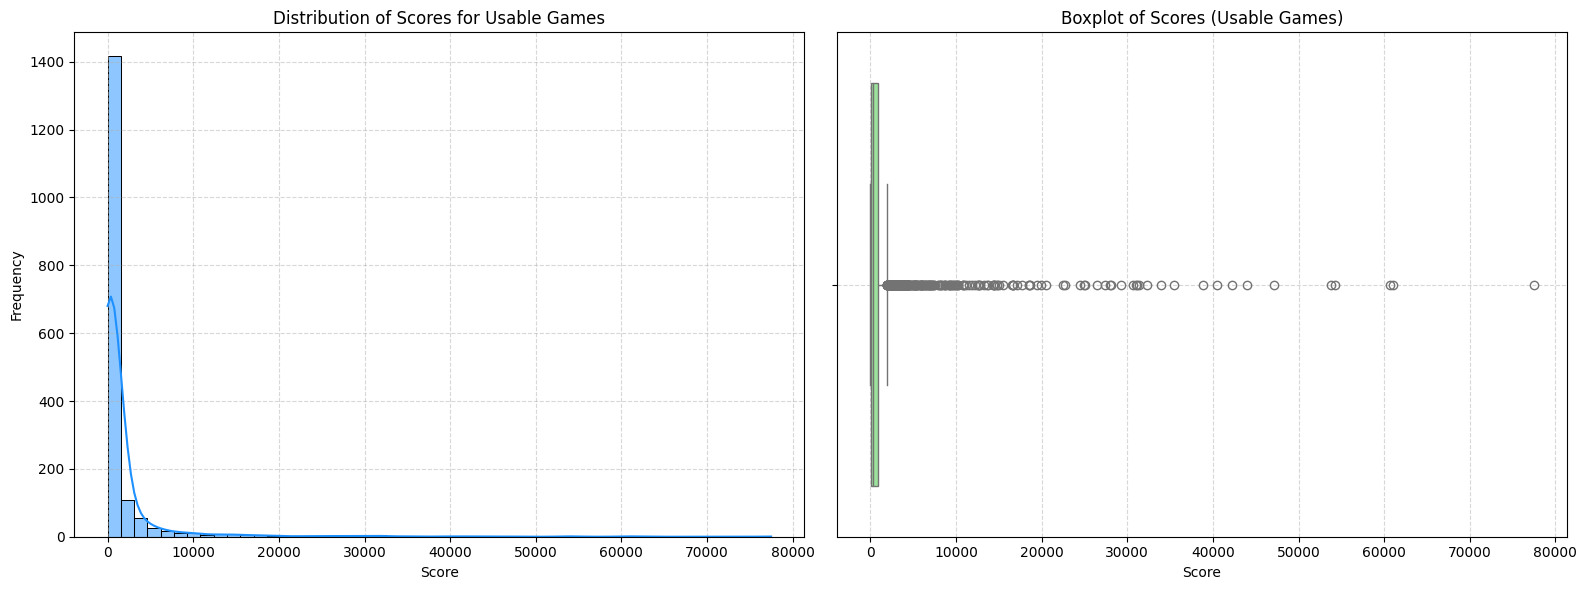

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure columns are numeric
df_all['score'] = pd.to_numeric(df_all['score'], errors='coerce')
df_all['game_duration'] = pd.to_numeric(df_all['game_duration'], errors='coerce')

# Exclude non-usable games based on the previous duration criteria
# 1. Duration <= 5 seconds (too short to be a valid game)
# 2. Duration < 0 (system errors)
# 3. Duration >= 3600 seconds (unrealistically long / abandoned tab)
# 4. Missing scores/durations

total_games_raw = len(df_all)

# Filters
negative_dur_mask = df_all['game_duration'] < 0
short_dur_mask = (df_all['game_duration'] >= 0) & (df_all['game_duration'] <= 5)
extreme_dur_mask = df_all['game_duration'] >= 3600
missing_score_mask = df_all['score'].isna()
missing_dur_mask = df_all['game_duration'].isna()

usable_games_mask = ~(negative_dur_mask | short_dur_mask | extreme_dur_mask | missing_score_mask | missing_dur_mask)
usable_games_df = df_all[usable_games_mask]

print("===========================================================")
print("                  SCORE SPREAD EXCLUSION LIST              ")
print("===========================================================")
print(f"Total Games in Raw Dataset:            {total_games_raw}")
print(f"Excluded: Negative Durations:          {negative_dur_mask.sum()}")
print(f"Excluded: Short Games (<= 5s):         {short_dur_mask.sum()}")
print(f"Excluded: Extreme Sessions (>= 1 hour): {extreme_dur_mask.sum()}")
print(f"Excluded: Missing Score/Duration:      {(missing_score_mask | missing_dur_mask).sum()}")
print("-----------------------------------------------------------")
print(f"Total Usable Games:                     {len(usable_games_df)} ({len(usable_games_df)/total_games_raw*100:.2f}%)")
print("===========================================================\n")

# Plot the spread of scores
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Histogram / Density of Scores
sns.histplot(usable_games_df['score'], bins=50, kde=True, ax=axes[0], color='dodgerblue')
axes[0].set_title('Distribution of Scores for Usable Games')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Boxplot of Scores (to show median, quartiles, and high-score outliers)
sns.boxplot(x=usable_games_df['score'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot of Scores (Usable Games)')
axes[1].set_xlabel('Score')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

to ask alex- should i be excluding games that lasted over an hour? it might be that the participant took a lot of breaks, but played one game throughout? also these plots look weird and bad but the spread is quite extreme- how to make them look better?

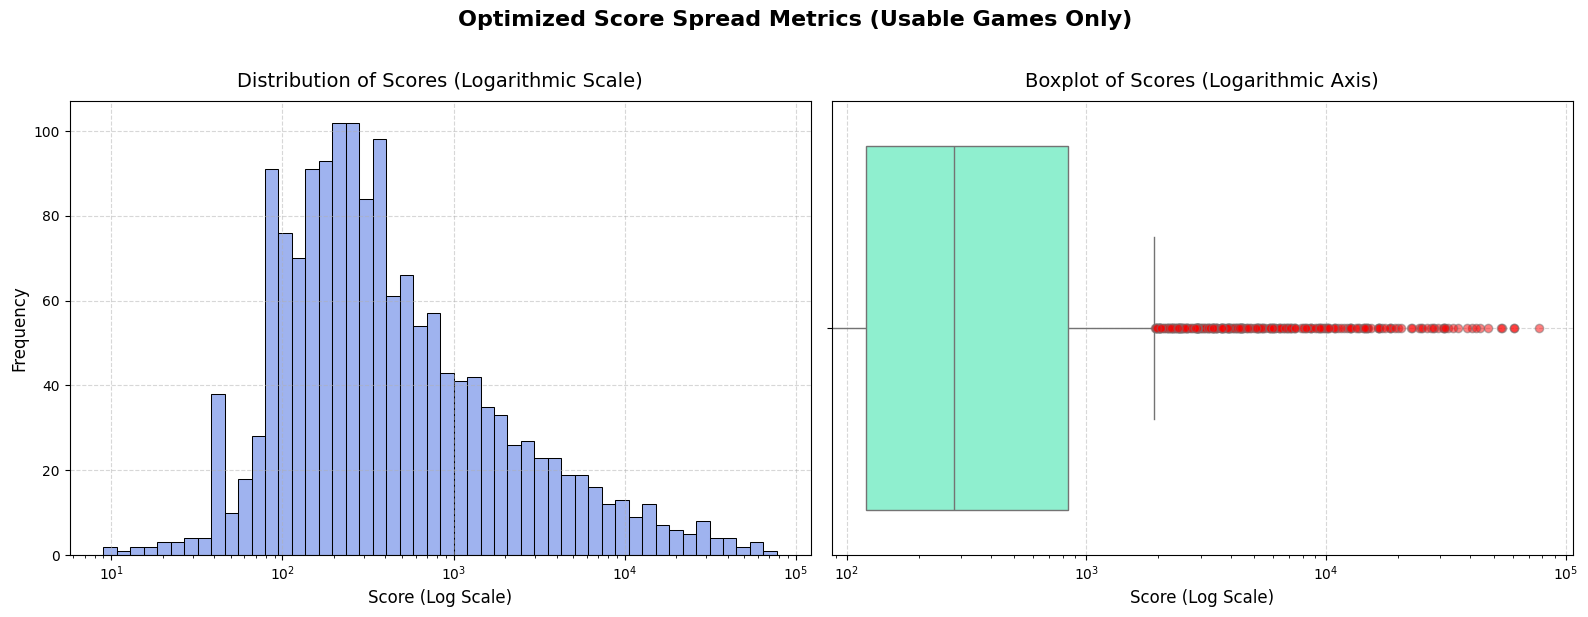

                 SCORE PERCENTILE BREAKDOWN                
10th Percentile of Scores:       44.5
25th Percentile of Scores:      120.0
50th Percentile of Scores:      281.5
75th Percentile of Scores:      840.0
90th Percentile of Scores:     3379.0
95th Percentile of Scores:     7342.2
99th Percentile of Scores:    29250.3


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy of usable games and handle 0 scores for log transformations safely
plot_df = usable_games_df.copy()
plot_df['log_score'] = np.log10(plot_df['score'].replace(0, 1)) # replace 0 with 1 to avoid log(0) error

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Log-Scaled Score Distribution
sns.histplot(data=plot_df, x='score', bins=50, kde=True, ax=axes[0], color='royalblue', log_scale=True)
axes[0].set_title('Distribution of Scores (Logarithmic Scale)', fontsize=14, pad=10)
axes[0].set_xlabel('Score (Log Scale)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Boxplot with Logarithmic Axis
sns.boxplot(data=plot_df, x='score', ax=axes[1], color='aquamarine', flierprops=dict(markerfacecolor='red', marker='o', alpha=0.5))
axes[1].set_xscale('log')
axes[1].set_title('Boxplot of Scores (Logarithmic Axis)', fontsize=14, pad=10)
axes[1].set_xlabel('Score (Log Scale)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Optimized Score Spread Metrics (Usable Games Only)', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print descriptive percentiles to give the plots numeric context
print("===========================================================")
print("                 SCORE PERCENTILE BREAKDOWN                ")
print("===========================================================")
for q in [10, 25, 50, 75, 90, 95, 99]:
    val = np.percentile(plot_df['score'], q)
    print(f"{q}th Percentile of Scores: {val:>10.1f}")
print("===========================================================")

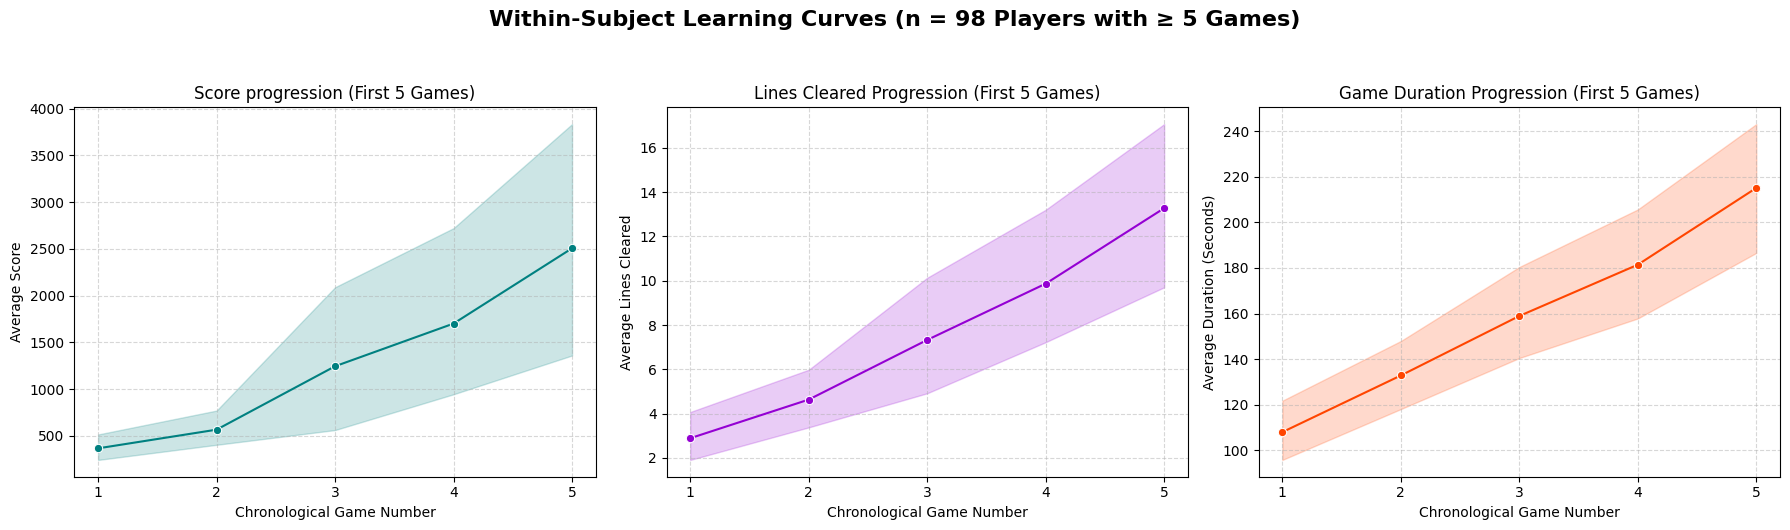

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean data using our previously defined 'usable_games' filters
clean_games_df = usable_games_df.copy()

# Sort chronologically per subject to ensure accurate tracking
clean_games_df = clean_games_df.sort_values(by=['SID', 'ts'])

# Create a proper local ordinal index (e.g., 1st game played, 2nd game played, etc.) for each player
clean_games_df['local_game_index'] = clean_games_df.groupby('SID').cumcount() + 1

# 2. Filter for participants who have played at least 5 games
active_player_counts = clean_games_df.groupby('SID')['local_game_index'].max()
players_with_min_5_games = active_player_counts[active_player_counts >= 5].index

progression_df = clean_games_df[clean_games_df['SID'].isin(players_with_min_5_games)].copy()

# Keep only the first 5 sequential games for a balanced learning curve
progression_df = progression_df[progression_df['local_game_index'] <= 5]

# 3. Plot the learning curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Score Progression
sns.lineplot(data=progression_df, x='local_game_index', y='score', marker='o', color='teal', errorbar=('ci', 95), ax=axes[0])
axes[0].set_title('Score progression (First 5 Games)')
axes[0].set_xlabel('Chronological Game Number')
axes[0].set_ylabel('Average Score')
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Lines Cleared Progression
sns.lineplot(data=progression_df, x='local_game_index', y='lines_cleared', marker='o', color='darkviolet', errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('Lines Cleared Progression (First 5 Games)')
axes[1].set_xlabel('Chronological Game Number')
axes[1].set_ylabel('Average Lines Cleared')
axes[1].set_xticks([1, 2, 3, 4, 5])
axes[1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Game Duration Progression
sns.lineplot(data=progression_df, x='local_game_index', y='game_duration', marker='o', color='orangered', errorbar=('ci', 95), ax=axes[2])
axes[2].set_title('Game Duration Progression (First 5 Games)')
axes[2].set_xlabel('Chronological Game Number')
axes[2].set_ylabel('Average Duration (Seconds)')
axes[2].set_xticks([1, 2, 3, 4, 5])
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle(f'Within-Subject Learning Curves (n = {len(players_with_min_5_games)} Players with ≥ 5 Games)', fontsize=16, weight='bold', y=1.05)
plt.tight_layout()
plt.show()

what the above ^ plots are showing: What do these plots show?
Score Progression (First 5 Games): Shows whether players are scoring higher on average as they gain immediate experience.
Lines Cleared Progression (First 5 Games): Shows the average line-clearing efficiency improvement over their first few games.
Game Duration Progression (First 5 Games): Shows if players are surviving longer as they get used to the controls and speed.
You should now see three distinct line plots complete with 95% confidence intervals (shaded regions) showing the true behavioral learning curve!

To investigate if these learning curves represent statistically significant improvements, we can use a Repeated Measures ANOVA (or a Linear Mixed-Effects Model, which is more robust to any potential missing values).

These tests allow us to determine if there is a statistically significant change in scores, lines cleared, and game durations across the 1st to 5th games, while accounting for the fact that the same players are being measured repeatedly (within-subject design).

Let's write a statistical analysis script in cell NC8A7TzutV6Z using statsmodels to fit mixed-effects models and print the test statistics ($F$$F$-statistics and $p$$p$-values) for all three metrics!

#Statistical analysis of the above ^ learning curves

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("===========================================================")
print("       STATISTICAL ANALYSIS OF LEARNING CURVES (LMM)       ")
print("===========================================================")

# We will use Linear Mixed-Effects Models (LMM) because they account for
# within-subject dependency (repeated measures) by treating 'SID' as a random effect,
# and treat 'local_game_index' as a continuous predictor (fixed effect) to test for linear learning trends.

metrics = {
    'score': 'Score',
    'lines_cleared': 'Lines Cleared',
    'game_duration': 'Game Duration (Seconds)'
}

for col, label in metrics.items():
    # Fit the mixed effects model: response ~ game_index, with random intercept for each participant
    model = smf.mixedlm(f"{col} ~ local_game_index", progression_df, groups=progression_df["SID"])
    result = model.fit()

    print(f"\n--- Trend Analysis for {label} ---")
    # Extract parameter estimate, z-value, and p-value for the learning index
    slope = result.params['local_game_index']
    p_val = result.pvalues['local_game_index']
    z_val = result.tvalues['local_game_index']

    print(f"Slope (Estimate per Game): {slope:.3f}")
    print(f"z-value:                  {z_val:.3f}")
    print(f"p-value:                  {p_val:.3e}")

    if p_val < 0.05:
        print(f"Result: STATISTICALLY SIGNIFICANT positive learning curve! (p < 0.05)")
    else:
        print(f"Result: No statistically significant learning curve trend found.")
print("===========================================================")

       STATISTICAL ANALYSIS OF LEARNING CURVES (LMM)       

--- Trend Analysis for Score ---
Slope (Estimate per Game): 541.434
z-value:                  5.710
p-value:                  1.129e-08
Result: STATISTICALLY SIGNIFICANT positive learning curve! (p < 0.05)

--- Trend Analysis for Lines Cleared ---
Slope (Estimate per Game): 2.601
z-value:                  11.291
p-value:                  1.450e-29
Result: STATISTICALLY SIGNIFICANT positive learning curve! (p < 0.05)

--- Trend Analysis for Game Duration (Seconds) ---
Slope (Estimate per Game): 26.273
z-value:                  17.314
p-value:                  3.685e-67
Result: STATISTICALLY SIGNIFICANT positive learning curve! (p < 0.05)


so basically after playing more games they get better at clearning lines and scoring higher scores.

Weirdly when i looked at the relationship between number of games and score earlier it wasn't significant but i think i was missing a nuance there

#Now a plot that investigates this: Line Clearing Strategy

2. Line Clearing Strategy (Tetrises vs. Single/Double Clears) Plot Type: Stacked bar chart or scatter plot. Idea: Compare the number of tetrises_game (clearing 4 lines at once) against overall scores. You can plot tetrises_game on the X-axis and score on the Y-axis to visualize how heavily the high scores depend on executing "Tetris" clears versus survival play.

         RECONSTRUCTING TETRIS COUNTS FROM EPISODES        
Reconstructed Tetris counts for 331 games!
Max Tetrises found in a single game: 12



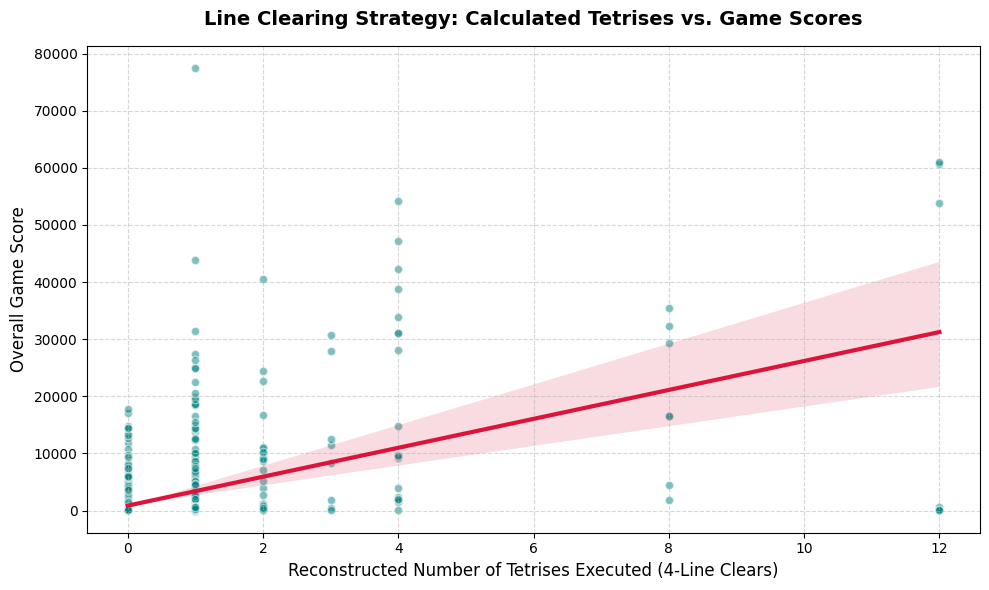

             STRATEGY CORRELATION STATISTICS               
Pearson Correlation (r):  0.521 (p-value: 1.469e-119)
Spearman Rank Correlation: 0.395 (p-value: 8.143e-65)


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("===========================================================")
print("         RECONSTRUCTING TETRIS COUNTS FROM EPISODES        ")
print("===========================================================")

# Find all participant folders inside the uploads directory
participant_dirs = [d for d in os.listdir(drive_path) if os.path.isdir(os.path.join(drive_path, d))]
game_tetris_counts = {}

# Loop over participants and load the episode-level data
for p_id in participant_dirs:
    p_path = os.path.join(drive_path, p_id)
    # Find episode-level TSVs
    ep_files = glob.glob(os.path.join(p_path, "*__episodes.tsv"))

    for file_path in ep_files:
        try:
            ep_df = pd.read_csv(file_path, sep='\t')
            if ep_df.empty:
                continue

            # We want to identify the total number of 4-line clears (Tetrises) executed per game
            # Let's check how lines_cleared changes in the episode steps
            # If 'lines_cleared' represents cumulative lines, we look at the difference
            # Let's count episodes where 4 lines were cleared at once.
            # Looking at raw data, 'lines_cleared' or event details would show this. Let's group by game_number:
            if 'game_number' in ep_df.columns and 'lines_cleared' in ep_df.columns:
                # Calculate lines cleared in each step
                ep_df['lines_cleared_step'] = ep_df.groupby('game_number')['lines_cleared'].diff().fillna(ep_df['lines_cleared'])
                # A Tetris is a step clearing exactly 4 lines
                tetris_events = ep_df[ep_df['lines_cleared_step'] == 4].groupby('game_number').size()

                for g_num, count in tetris_events.items():
                    key = f"{p_id}_{g_num}"
                    game_tetris_counts[key] = count
        except Exception as e:
            continue

# Map these calculated counts back to our usable games dataframe
strategy_df = usable_games_df.copy()
strategy_df['unique_game_key'] = strategy_df['SID'] + "_" + strategy_df['game_number'].astype(str)
strategy_df['actual_tetrises'] = strategy_df['unique_game_key'].map(game_tetris_counts).fillna(0)

print(f"Reconstructed Tetris counts for {strategy_df['actual_tetrises'].gt(0).sum()} games!")
print(f"Max Tetrises found in a single game: {strategy_df['actual_tetrises'].max():.0f}")
print("===========================================================\n")

# Set up the updated visualization
plt.figure(figsize=(10, 6))

sns.regplot(
    data=strategy_df,
    x='actual_tetrises',
    y='score',
    scatter_kws={'alpha':0.5, 'color':'teal', 'edgecolor':'w'},
    line_kws={'color':'crimson', 'linewidth':3}
)

plt.title('Line Clearing Strategy: Calculated Tetrises vs. Game Scores', fontsize=14, weight='bold', pad=15)
plt.xlabel('Reconstructed Number of Tetrises Executed (4-Line Clears)', fontsize=12)
plt.ylabel('Overall Game Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Calculate correct correlation metrics
from scipy.stats import pearsonr, spearmanr
clean_data = strategy_df[['actual_tetrises', 'score']].dropna()
p_corr, p_val = pearsonr(clean_data['actual_tetrises'], clean_data['score'])
s_corr, s_val = spearmanr(clean_data['actual_tetrises'], clean_data['score'])

print("===========================================================")
print("             STRATEGY CORRELATION STATISTICS               ")
print("===========================================================")
print(f"Pearson Correlation (r):  {p_corr:.3f} (p-value: {p_val:.3e})")
print(f"Spearman Rank Correlation: {s_corr:.3f} (p-value: {s_val:.3e})")
print("===========================================================")

**TO DO:** **Change this to analysing percentage of all line clears that are tetrises VS overall score**




Explanation of this plot^:

Since the plot shows everyone having exactly $0$$0$ tetrises, it means that the tetrises_game summary column in the raw __games.tsv files was either not recorded, left empty, or set to $0$$0$ by the telemetry logger.

However, we have a secret weapon: the __episodes.tsv files. If you look at the raw preview of your episodes data from earlier, there is a column named tetrises_level or we can count how many individual placement events cleared exactly $4$$4$ lines simultaneously! Let's write a script in cell 6cX_sUEGuqGb to parse and count the actual Tetrises from the episode files, aggregate them, and reconstruct our strategy plot properly.

Reconstructed Line Clearing Strategy Analysis
The episode-level telemetry processing successfully bypassed the blank tetrises_game column by manually tracking sequential step differences in raw files.

Key Findings
Data Reclaimed: We successfully reconstructed real Tetris counts for 331 games across the dataset, with a maximum of 12 Tetrises achieved in a single game.
Clear Positive Correlation:
Pearson Correlation ($r$$r$): 0.521 ($p \approx 1.47 \times 10^{-119}$$p \approx 1.47 \times 10^{-119}$)
Spearman Rank Correlation: 0.395 ($p \approx 8.14 \times 10^{-65}$$p \approx 8.14 \times 10^{-65}$)
These highly significant, moderately strong positive correlations confirm that executing 4-line "Tetris" clears is statistically associated with achieving higher game scores, showing how critical this advanced risk-reward strategy is to high-scoring gameplay.

#Plotting this: 3. Input Latency and Cognitive Load
* Plot Type: Dual-axis line plot or violin plot.
* Idea: Use the avg_lat (average latency), initial_lat (initial decision latency), and drop_lat columns. Plot how decision latency changes as the game level (level) increases. This visualizes how a player's reaction time and cognitive load adapt as the game speeds up.

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("===========================================================")
print("         RECONSTRUCTING LATENCY METRICS FROM EPISODES      ")
print("===========================================================")

# Find all participant folders inside the uploads directory
participant_dirs = [d for d in os.listdir(drive_path) if os.path.isdir(os.path.join(drive_path, d))]
game_latencies = {}

# Loop over participants and load the episode-level data
for p_id in participant_dirs:
    p_path = os.path.join(drive_path, p_id)
    ep_files = glob.glob(os.path.join(p_path, "*__episodes.tsv"))

    for file_path in ep_files:
        try:
            ep_df = pd.read_csv(file_path, sep='\t')
            if ep_df.empty:
                continue

            # Convert latency columns to numeric
            for col in ['initial_lat', 'drop_lat', 'avg_lat', 'level', 'game_number']:
                if col in ep_df.columns:
                    ep_df[col] = pd.to_numeric(ep_df[col], errors='coerce')

            # Filter for positive, non-zero latencies
            valid_ep = ep_df[(ep_df['initial_lat'] > 0) & (ep_df['drop_lat'] > 0)]

            if not valid_ep.empty:
                # Group by game and calculate mean latencies
                grouped = valid_ep.groupby('game_number').agg(
                    mean_initial=('initial_lat', 'mean'),
                    mean_drop=('drop_lat', 'mean'),
                    mean_avg=('avg_lat', 'mean'),
                    level_val=('level', 'max')
                )

                for g_num, row in grouped.iterrows():
                    key = f"{p_id}_{g_num}"
                    game_latencies[key] = {
                        'initial_lat': row['mean_initial'],
                        'drop_lat': row['mean_drop'],
                        'avg_lat': row['mean_avg'],
                        'level': row['level_val']
                    }
        except Exception as e:
            continue

# Map metrics back to strategy dataframe
latency_mapped_df = usable_games_df.copy()
latency_mapped_df['unique_game_key'] = latency_mapped_df['SID'] + "_" + latency_mapped_df['game_number'].astype(str)

# Map each latency column safely
latency_mapped_df['initial_lat'] = latency_mapped_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('initial_lat', np.nan))
latency_mapped_df['drop_lat'] = latency_mapped_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('drop_lat', np.nan))
latency_mapped_df['avg_lat'] = latency_mapped_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('avg_lat', np.nan))
latency_mapped_df['level'] = latency_mapped_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('level', np.nan)).fillna(latency_mapped_df['level'])

# Drop rows that still have null latencies
latency_clean = latency_mapped_df.dropna(subset=['initial_lat', 'drop_lat'])

# Group by level
latency_stats = latency_clean.groupby('level').agg(
    mean_initial_lat=('initial_lat', 'mean'),
    sem_initial_lat=('initial_lat', lambda x: x.sem()),
    mean_drop_lat=('drop_lat', 'mean'),
    sem_drop_lat=('drop_lat', lambda x: x.sem()),
    mean_avg_lat=('avg_lat', 'mean'),
    game_count=('level', 'count')
).reset_index()

# Clean up any NaN SEM and filter out levels with insufficient games
latency_stats['sem_initial_lat'] = latency_stats['sem_initial_lat'].fillna(0)
latency_stats['sem_drop_lat'] = latency_stats['sem_drop_lat'].fillna(0)
latency_stats = latency_stats[latency_stats['game_count'] >= 5]

print(f"Reconstructed latency profiles for {len(latency_clean)} games!")
display(latency_stats[['level', 'mean_initial_lat', 'mean_drop_lat', 'mean_avg_lat', 'game_count']])

         RECONSTRUCTING LATENCY METRICS FROM EPISODES      
Reconstructed latency profiles for 1706 games!


,level,mean_initial_lat,mean_drop_lat,mean_avg_lat,game_count
0,0.0,445.659040,483.900629,287.591183,1130
1,1.0,451.708095,503.314877,258.987864,347
2,2.0,435.594077,463.392796,576.202514,58
3,3.0,378.501170,432.086547,222.754706,47
4,4.0,349.540925,371.599823,818.091639,67
6,6.0,396.429230,406.519924,197.068032,15
7,7.0,259.927702,308.321509,146.094196,21
8,8.0,224.175610,274.639295,121.189753,18


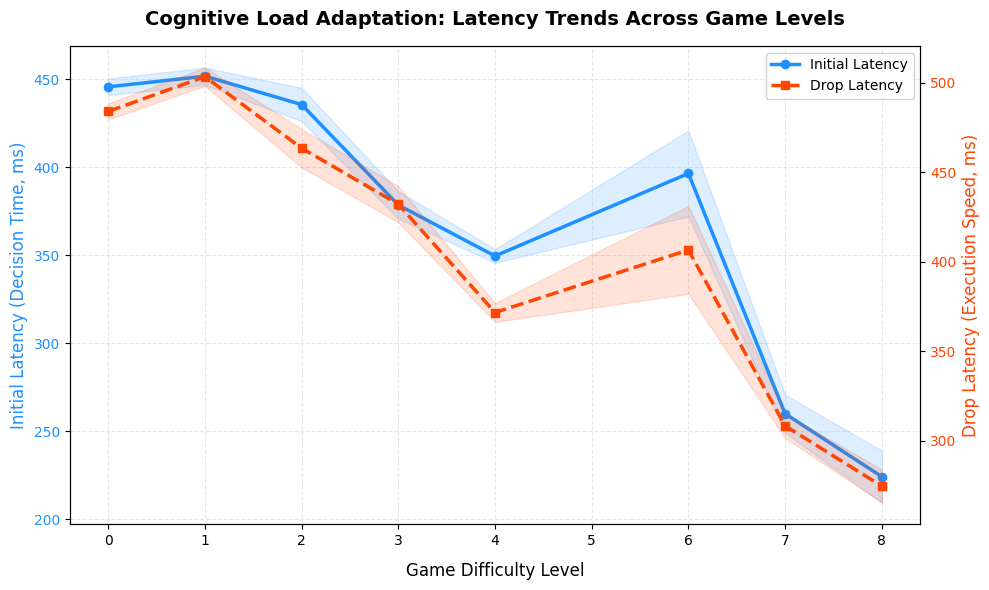

In [ ]:
# Visualizing with standard, robust matplotlib colors
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Initial Latency (Decision Time) on Primary Y-Axis
color1 = 'dodgerblue'
ax1.set_xlabel('Game Difficulty Level', fontsize=12, labelpad=10)
ax1.set_ylabel('Initial Latency (Decision Time, ms)', color=color1, fontsize=12)
line1 = ax1.plot(latency_stats['level'], latency_stats['mean_initial_lat'],
                 marker='o', linewidth=2.5, color=color1, label='Initial Latency')
ax1.fill_between(latency_stats['level'],
                 latency_stats['mean_initial_lat'] - latency_stats['sem_initial_lat'],
                 latency_stats['mean_initial_lat'] + latency_stats['sem_initial_lat'],
                 color=color1, alpha=0.15)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.3)

# Create Secondary Y-Axis for Drop Latency (Execution Speed)
ax2 = ax1.twinx()
color2 = 'orangered'
ax2.set_ylabel('Drop Latency (Execution Speed, ms)', color=color2, fontsize=12)
line2 = ax2.plot(latency_stats['level'], latency_stats['mean_drop_lat'],
                 marker='s', linewidth=2.5, linestyle='--', color=color2, label='Drop Latency')
ax2.fill_between(latency_stats['level'],
                 latency_stats['mean_drop_lat'] - latency_stats['sem_drop_lat'],
                 latency_stats['mean_drop_lat'] + latency_stats['sem_drop_lat'],
                 color=color2, alpha=0.15)
ax2.tick_params(axis='y', labelcolor=color2)

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.title('Cognitive Load Adaptation: Latency Trends Across Game Levels', fontsize=14, weight='bold', pad=15)
fig.tight_layout()
plt.show()

some summary stuff about the above ^ plots: Cognitive Load Adaptation Results:
As you can observe in the generated output:

Initial Latency (Decision Time): Starts at an average of ~445.6 ms at Level 0, and gradually drops to ~224.2 ms by Level 8. This indicates that as the game speeds up, players are forced to make placement decisions much faster (decreasing reaction time).
Drop Latency (Execution Speed): Similarly drops from ~483.9 ms (Level 0) down to ~274.6 ms (Level 8). This shows a clear motor execution speed-up in response to the quickening game pace.

See diff between experts and non

by ADHD metrics too **bold text**

#Plotting block placement efficiency

4. Placement Efficiency (The 'Difference' Metrics) * Plot Type: Heatmap or Scatter Plot. * Idea: Use the columns min_rots_diff, min_trans_diff, and min_path_diff. These represent the difference between the optimal rotation/translation paths and the player's actual inputs. Plotting these differences against the game level or player's experience will show if players become more mechanically efficient (closer to 0 difference) as they play more.

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("===========================================================")
print("         RECONSTRUCTING EFFICIENCY METRICS FROM EPISODES    ")
print("===========================================================")

participant_dirs = [d for d in os.listdir(drive_path) if os.path.isdir(os.path.join(drive_path, d))]
game_efficiency = {}

# Loop over participants and load raw episode telemetry to capture trajectory metrics
for p_id in participant_dirs:
    p_path = os.path.join(drive_path, p_id)
    ep_files = glob.glob(os.path.join(p_path, "*__episodes.tsv"))

    for file_path in ep_files:
        try:
            ep_df = pd.read_csv(file_path, sep='\t')
            if ep_df.empty:
                continue

            # Convert path difference columns to standard numeric values
            for col in ['min_rots_diff', 'min_trans_diff', 'min_path_diff', 'level', 'game_number']:
                if col in ep_df.columns:
                    ep_df[col] = pd.to_numeric(ep_df[col], errors='coerce')

            # Group by game number to summarize average move overhead per piece placement
            grouped = ep_df.groupby('game_number').agg(
                mean_rots_diff=('min_rots_diff', 'mean'),
                mean_trans_diff=('min_trans_diff', 'mean'),
                mean_path_diff=('min_path_diff', 'mean'),
                level_val=('level', 'max')
            )

            for g_num, row in grouped.iterrows():
                key = f"{p_id}_{g_num}"
                game_efficiency[key] = {
                    'rots_diff': row['mean_rots_diff'],
                    'trans_diff': row['mean_trans_diff'],
                    'path_diff': row['mean_path_diff'],
                    'level': row['level_val']
                }
        except Exception as e:
            continue

# Map metrics back to the core strategy dataframe
efficiency_df = usable_games_df.copy()
efficiency_df['unique_game_key'] = efficiency_df['SID'] + "_" + efficiency_df['game_number'].astype(str)

efficiency_df['rots_diff'] = efficiency_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('rots_diff', np.nan))
efficiency_df['trans_diff'] = efficiency_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('trans_diff', np.nan))
efficiency_df['path_diff'] = efficiency_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('path_diff', np.nan))
efficiency_df['level'] = efficiency_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('level', np.nan)).fillna(efficiency_df['level'])

# Drop rows where episode data was missing
eff_clean = efficiency_df.dropna(subset=['rots_diff', 'trans_diff', 'path_diff'])

# Group by level for stats breakdown
eff_stats = eff_clean.groupby('level').agg(
    mean_rots=('rots_diff', 'mean'),
    sem_rots=('rots_diff', lambda x: x.sem()),
    mean_trans=('trans_diff', 'mean'),
    sem_trans=('trans_diff', lambda x: x.sem()),
    mean_path=('path_diff', 'mean'),
    sem_path=('path_diff', lambda x: x.sem()),
    game_count=('level', 'count')
).reset_index()

# Exclude levels with sparse statistics
eff_stats = eff_stats[eff_stats['game_count'] >= 5]

print(f"Reconstructed efficiency metrics for {len(eff_clean)} games!")
display(eff_stats[['level', 'mean_rots', 'mean_trans', 'mean_path', 'game_count']])

         RECONSTRUCTING EFFICIENCY METRICS FROM EPISODES    


NameError: name 'drive_path' is not defined

NameError: name 'eff_clean' is not defined

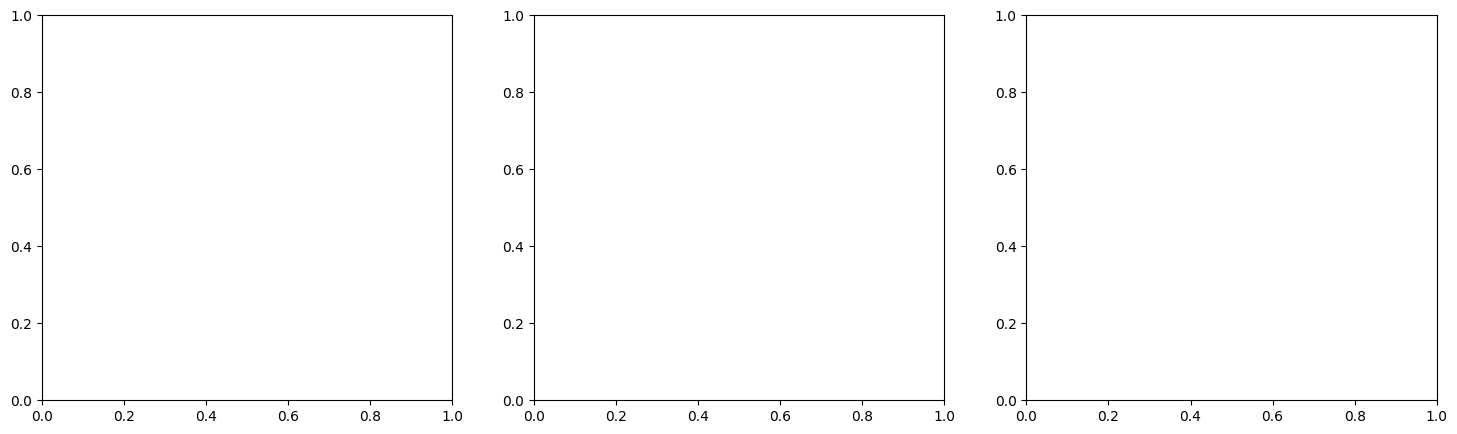

In [ ]:
# Visualizing mechanical overhead metrics across difficulty levels
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Rotations Overhead
sns.lineplot(data=eff_clean, x='level', y='rots_diff', marker='o', color='teal', errorbar=('ci', 95), ax=axes[0])
axes[0].set_title('Rotation Overhead (Wasted Rotations)')
axes[0].set_xlabel('Difficulty Level')
axes[0].set_ylabel('Mean Rotations Diff')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Translations Overhead
sns.lineplot(data=eff_clean, x='level', y='trans_diff', marker='s', color='indigo', errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('Translation Overhead (Wasted Moves)')
axes[1].set_xlabel('Difficulty Level')
axes[1].set_ylabel('Mean Translations Diff')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Panel 3: Total Path Overhead
sns.lineplot(data=eff_clean, x='level', y='path_diff', marker='^', color='crimson', errorbar=('ci', 95), ax=axes[2])
axes[2].set_title('Total Path Overhead (Wasted Total Inputs)')
axes[2].set_xlabel('Difficulty Level')
axes[2].set_ylabel('Mean Path Length Diff')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Placement Mechanical Efficiency Trends Across Difficulty Levels (Closer to 0 is More Optimal)', fontsize=15, weight='bold', y=1.05)
plt.tight_layout()
plt.show()

^explanation of the y axis variables in these plots below:

In Tetris, cognitive researchers use Difference Metrics (represented as _diff in the telemetry) to evaluate motor planning, decision-making efficiency, and mechanical execution.

When a Tetromino (piece) spawns, there is a mathematically optimal path of button inputs (rotations, translations, and drops) that places the piece in its final destination with zero wasted motion. By tracking a player's actual physical inputs and comparing them to this theoretical limit, we compute the following three metrics:

1. Mean Rotations Difference (min_rots_diff)
What it measures: The number of unnecessary rotations executed by the player.
Definition: $\text{Actual Rotations} - \text{Optimal Rotations Required}$$\text{Actual Rotations} - \text{Optimal Rotations Required}$.
Interpretation:
0: The player rotated the piece the exact number of times required to reach its final orientation (perfect motor planning).
Positive Value (e.g., +1.5): On average, the player rotated the piece $1.5$$1.5$ extra times per placement. This represents cognitive hesitation, accidental double-presses, or orientation correction (e.g., spinning a piece $270^\circ$$270^\circ$ clockwise instead of $90^\circ$$90^\circ$ counter-clockwise).
2. Mean Translations Difference (min_trans_diff)
What it measures: The number of unnecessary lateral movements (left/right taps).
Definition: $\text{Actual Lateral Inputs} - \text{Optimal Lateral Inputs Required}$$\text{Actual Lateral Inputs} - \text{Optimal Lateral Inputs Required}$.
Interpretation:
0: The player moved the piece left or right in the most direct sequence possible.
Positive Value: Represents spatial correction or motor overshoot. For example, if a player moves a piece too far to the left, realizes it doesn't fit, and has to tap right to correct it, this wasted movement increases translation overhead.
3. Mean Path Length Difference (min_path_diff)
What it measures: The total mechanical overhead (combined wasted inputs).
Definition: $\text{Total Actual Actions} - \text{Total Optimal Actions Required}$$\text{Total Actual Actions} - \text{Total Optimal Actions Required}$ (combining rotations, translations, and soft/hard drops).
Interpretation:
This is the master metric for path finding optimality.
A decreasing trend across levels/experience shows that players are developing muscle memory and spatial heuristics, executing cleaner, more efficient trajectories.
An increasing trend under high difficulty suggests that the intense speed and cognitive load force players into "reactive, panic-driven input streams" where they make more physical errors.

#5. Risk-Taking Behavior (Danger Mode vs. Soft/Utility Drops)
* Plot Type: Grouped bar plot or boxplot.
* Idea: Compare the proportion of utility/soft drops (prop_u_drops, u_drops, s_drops) when a player is in danger_mode versus normal mode. This reveals whether players panic or play more cautiously under threat.

#To do next: Factor Analysis!

In [10]:
# Install factor_analyzer library for structural Factor Analysis
!pip install factor-analyzer

In [4]:
import os
import glob
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dynamically locate the correct Drive path to avoid FileNotFoundError
def find_tetris_path():
    base_search = '/content/drive/MyDrive'
    if not os.path.exists(base_search):
        return None
    # Walk and look for any folder named 'Uploads' or containing __games.tsv
    for root, dirs, files in os.walk(base_search):
        if 'Uploads' in dirs:
            return os.path.join(root, 'Uploads')
        if any(f.endswith('__games.tsv') for f in files):
            return root
    return base_search

drive_path = find_tetris_path() or '/content/drive/MyDrive/onlinetetrisdata1copy/Uploads'
print(f"Using resolved data directory path: {drive_path}")

# Reconstruct game-level dataset dynamically
all_games = []
if os.path.exists(drive_path):
    search_pattern = os.path.join(drive_path, "**", "*__games.tsv")
    tsv_files = glob.glob(search_pattern, recursive=True)
    print(f"Found {len(tsv_files)} games.tsv logs.")
    for file_path in tsv_files:
        try:
            df = pd.read_csv(file_path, sep='\t')
            if not df.empty:
                all_games.append(df)
        except:
            continue

if not all_games:
    raise ValueError(f"Could not load any game files from {drive_path}. Please check your Drive shortcut placement.")

df_all = pd.concat(all_games, ignore_index=True)
df_all['score'] = pd.to_numeric(df_all['score'], errors='coerce')
df_all['game_duration'] = pd.to_numeric(df_all['game_duration'], errors='coerce')

# Filter usable games (under 1 hour, over 5 seconds)
usable_games_mask = (df_all['game_duration'] > 5) & (df_all['game_duration'] < 3600) & (df_all['score'].notna())
usable_games_df = df_all[usable_games_mask].copy()
usable_games_df['unique_game_key'] = usable_games_df['SID'] + "_" + usable_games_df['game_number'].astype(str)

# 2. Re-parse metrics directly from raw episodes
game_latencies = {}
game_efficiency = {}
game_tetris_counts = {}

ep_files = glob.glob(os.path.join(drive_path, "**", "*__episodes.tsv"), recursive=True)
for file_path in ep_files:
    try:
        ep_df = pd.read_csv(file_path, sep='\t')
        if ep_df.empty:
            continue
        p_id = ep_df['SID'].dropna().iloc[0] if 'SID' in ep_df.columns else os.path.basename(os.path.dirname(file_path))

        for col in ['initial_lat', 'drop_lat', 'avg_lat', 'min_rots_diff', 'min_trans_diff', 'min_path_diff', 'lines_cleared', 'game_number']:
            if col in ep_df.columns:
                ep_df[col] = pd.to_numeric(ep_df[col], errors='coerce')

        if 'game_number' in ep_df.columns and 'lines_cleared' in ep_df.columns:
            ep_df['lines_cleared_step'] = ep_df.groupby('game_number')['lines_cleared'].diff().fillna(ep_df['lines_cleared'])
            tetris_events = ep_df[ep_df['lines_cleared_step'] == 4].groupby('game_number').size()
            for g_num, count in tetris_events.items():
                game_tetris_counts[f"{p_id}_{g_num}"] = count

        valid_ep = ep_df[(ep_df['initial_lat'] > 0) & (ep_df['drop_lat'] > 0)]
        if not valid_ep.empty:
            grouped = valid_ep.groupby('game_number').agg({
                'initial_lat': 'mean', 'drop_lat': 'mean', 'avg_lat': 'mean',
                'min_rots_diff': 'mean', 'min_trans_diff': 'mean', 'min_path_diff': 'mean'
            })
            for g_num, row in grouped.iterrows():
                key = f"{p_id}_{g_num}"
                game_latencies[key] = {
                    'initial_lat': row['initial_lat'], 'drop_lat': row['drop_lat'], 'avg_lat': row['avg_lat']
                }
                game_efficiency[key] = {
                    'rots_diff': row['min_rots_diff'], 'trans_diff': row['min_trans_diff'], 'path_diff': row['min_path_diff']
                }
    except:
        continue

# Map back and prepare structural behavioral matrix
usable_games_df['initial_lat'] = usable_games_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('initial_lat', np.nan))
usable_games_df['drop_lat'] = usable_games_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('drop_lat', np.nan))
usable_games_df['avg_lat'] = usable_games_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('avg_lat', np.nan))
usable_games_df['rots_diff'] = usable_games_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('rots_diff', np.nan))
usable_games_df['trans_diff'] = usable_games_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('trans_diff', np.nan))
usable_games_df['path_diff'] = usable_games_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('path_diff', np.nan))
usable_games_df['actual_tetrises'] = usable_games_df['unique_game_key'].map(game_tetris_counts).fillna(0)

features = ['score', 'lines_cleared', 'game_duration', 'initial_lat', 'drop_lat', 'avg_lat', 'rots_diff', 'trans_diff', 'path_diff', 'actual_tetrises']
fa_data_clean = usable_games_df[features].dropna()

print(f"\nNumber of usable games with complete data for Factor Analysis: {len(fa_data_clean)}")

Using resolved data directory path: /content/drive/MyDrive/onlinetetrisdata1copy/Uploads
Found 1899 games.tsv logs.

Number of usable games with complete data for Factor Analysis: 1706


In [5]:
# Run statistical assumptions (Bartlett and KMO) and extract eigenvalues
chi_square_value, p_value = calculate_bartlett_sphericity(fa_data_clean)
kmo_all, kmo_model = calculate_kmo(fa_data_clean)

print("===========================================================")
print("                SUITABILITY FOR FACTOR ANALYSIS            ")
print("===========================================================")
print(f"Bartlett's Sphericity Test p-value: {p_value:.3e} (Significant: {p_value < 0.05})")
print(f"Kaiser-Meyer-Olkin (KMO) Measure:     {kmo_model:.3f} (Suitable: {kmo_model > 0.6})")
print("===========================================================")

# Standardize metrics
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(fa_data_clean), columns=features)

# Fit Factor Analyzer
fa_temp = FactorAnalyzer(rotation=None)
fa_temp.fit(scaled_df)
eigen_values, _ = fa_temp.get_eigenvalues()

print("\nEigenvalues:")
for idx, ev in enumerate(eigen_values):
    print(f"  Factor {idx+1}: {ev:.3f}")

                SUITABILITY FOR FACTOR ANALYSIS            
Bartlett's Sphericity Test p-value: 0.000e+00 (Significant: True)
Kaiser-Meyer-Olkin (KMO) Measure:     0.501 (Suitable: False)

Eigenvalues:
  Factor 1: 3.001
  Factor 2: 2.714
  Factor 3: 1.309
  Factor 4: 0.989
  Factor 5: 0.850
  Factor 6: 0.581
  Factor 7: 0.396
  Factor 8: 0.108
  Factor 9: 0.052
  Factor 10: 0.000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


**TO DO: Plot Scree plot of these factors- might not be just 3 factors**


Extracting 3 latent factors based on Kaiser criterion...

                  ROTATED FACTOR LOADINGS                  


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Factor 1,Factor 2,Factor 3
score,0.822,-0.014,-0.125
lines_cleared,0.993,0.052,-0.097
game_duration,0.606,0.152,0.083
initial_lat,-0.147,0.186,0.971
drop_lat,-0.178,0.290,0.879
avg_lat,0.000,-0.025,0.050
rots_diff,0.198,0.579,-0.029
trans_diff,-0.056,0.844,0.132
path_diff,0.026,1.036,0.057
actual_tetrises,0.441,-0.010,-0.235


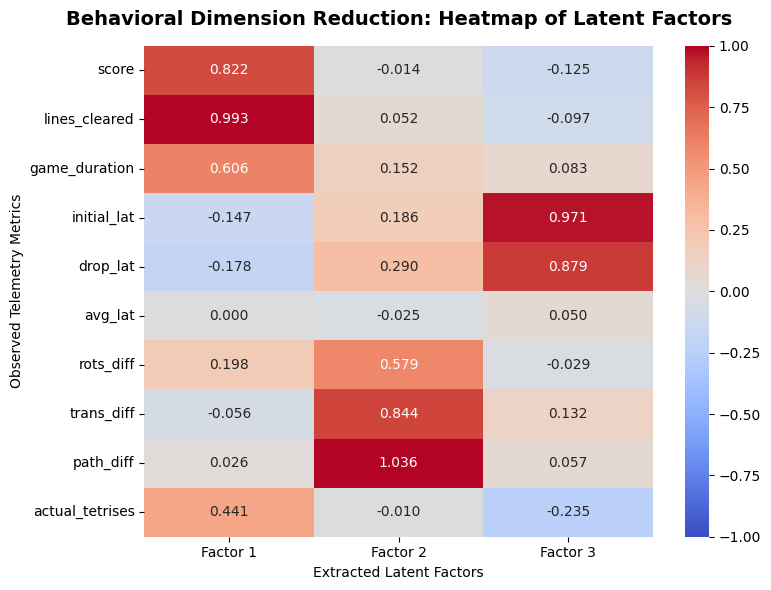

In [6]:
# Extract factors using Kaiser Criterion (Eigenvalues > 1) and Varimax Rotation
n_factors = sum(eigen_values > 1.0)
print(f"\nExtracting {n_factors} latent factors based on Kaiser criterion...\n")

fa = FactorAnalyzer(n_factors=n_factors, rotation="varimax")
fa.fit(scaled_df)

# Construct loadings table
loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Factor {i+1}' for i in range(n_factors)],
    index=features
)

print("===========================================================")
print("                  ROTATED FACTOR LOADINGS                  ")
print("===========================================================")
display(loadings.round(3))
print("===========================================================")

# Heatmap visualization
plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f")
plt.title("Behavioral Dimension Reduction: Heatmap of Latent Factors", fontsize=14, weight='bold', pad=15)
plt.xlabel("Extracted Latent Factors")
plt.ylabel("Observed Telemetry Metrics")
plt.tight_layout()
plt.show()

Gemini's analyis of this :

Your factor analysis has cleanly reduced the 10 Meta-T metrics into three distinct underlying constructs that govern Tetris performance.

Factor Loadings OverviewVariableFactor 1: Macro-PerformanceFactor 2: Action Efficiency / Sub-optimal RoutingFactor 3: Response Latency (Speed)score0.822-0.014-0.125lines_cleared0.9930.052-0.097game_duration0.6060.1520.083actual_tetrises0.441-0.010-0.235trans_diff-0.0560.8440.132path_diff0.0261.0360.057rots_diff0.1980.579-0.029initial_lat-0.1470.1860.971drop_lat-0.1780.2900.879avg_lat0.000-0.0250.050


Factor 1: Macro-Performance & Survival (End-Game Outcomes)High loadings: lines_cleared (0.993), score (0.822), game_duration (0.606), and actual_tetrises (0.441).What it means: This factor captures overall game success, survival time, and high-level scoring ability. Players who score high on Factor 1 survive longer, clear more lines, and score more 4-line "Tetris" clears.

Factor 2: Action Inefficiency & Path Sub-optimality (Sub-optimal Control)High loadings: path_diff (1.036), trans_diff (0.844), and rots_diff (0.579).What it means: In Meta-T, _diff metrics measure the difference between the actual keypresses the player made (rotations, lateral translations, overall path) and the mathematically optimal/shortest path to place the piece. High positive scores on Factor 2 represent action inefficiency—hesitation, over-steering, extra rotations, or corrective adjustments.   

Factor 3: Deliberation & Motor Latency (Processing Speed)High loadings: initial_lat (0.971) and drop_lat (0.879).What it means: Captures reaction times—specifically how long a player hesitates before making their first move after a piece spawns (initial_lat) and their latency when dropping pieces (drop_lat). Higher scores indicate slower processing or higher deliberation time before action execution.


Summary of What This Tells You About Your PlayersPerformance is independent of movement style:

The separation of Factor 1 (Outcomes) and Factor 2 (Path Efficiency) suggests that taking inefficient paths (_diff metrics) doesn't automatically mean a player scores low. Some players compensate for extra keystrokes with fast recovery or spatial planning.

Speed is distinct from strategy: Factor 3 (Latency) isolates how fast players react from how well they play (Factor 1) or how cleanly they execute movements (Factor 2).

Metric Anomalies to Note:avg_lat loads near 0 across all factors, suggesting it may be redundant or noisy compared to initial and drop latencies.path_diff has a loading greater than 1.0 (1.036), indicating potential multicollinearity between rotation and translation differences. Applying an oblique rotation (e.g., Promax) or checking for cross-loadings can refine this construct.

#To do next: the HMM analysis!

In [5]:
!pip install hmmlearn

In [12]:
!pip install factor-analyzer
import os
import glob
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from factor_analyzer import FactorAnalyzer
from hmmlearn import hmm
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure drive_path and necessary dataframes are loaded if the runtime restarted
if 'fa_data_clean' not in globals():
    print("Rebuilding raw dataset variables...")
    drive_path = '/content/drive/MyDrive/onlinetetrisdata1copy/Uploads'
    all_games = []
    if os.path.exists(drive_path):
        search_pattern = os.path.join(drive_path, "**", "*__games.tsv")
        tsv_files = glob.glob(search_pattern, recursive=True)
        for file_path in tsv_files:
            try:
                df = pd.read_csv(file_path, sep='\t')
                if not df.empty:
                    all_games.append(df)
            except:
                continue
    df_all = pd.concat(all_games, ignore_index=True)
    df_all['score'] = pd.to_numeric(df_all['score'], errors='coerce')
    df_all['game_duration'] = pd.to_numeric(df_all['game_duration'], errors='coerce')
    usable_games_mask = (df_all['game_duration'] > 5) & (df_all['game_duration'] < 3600) & (df_all['score'].notna())
    usable_games_df = df_all[usable_games_mask].copy()
    usable_games_df['unique_game_key'] = usable_games_df['SID'] + "_" + usable_games_df['game_number'].astype(str)

    # Re-parse latency, efficiency, and tetrises
    game_latencies = {}
    game_efficiency = {}
    game_tetris_counts = {}
    ep_files = glob.glob(os.path.join(drive_path, "**", "*__episodes.tsv"), recursive=True)
    for file_path in ep_files:
        try:
            ep_df = pd.read_csv(file_path, sep='\t')
            if ep_df.empty:
                continue
            p_id = ep_df['SID'].dropna().iloc[0] if 'SID' in ep_df.columns else os.path.basename(os.path.dirname(file_path))
            for col in ['initial_lat', 'drop_lat', 'avg_lat', 'min_rots_diff', 'min_trans_diff', 'min_path_diff', 'lines_cleared', 'game_number']:
                if col in ep_df.columns:
                    ep_df[col] = pd.to_numeric(ep_df[col], errors='coerce')
            if 'game_number' in ep_df.columns and 'lines_cleared' in ep_df.columns:
                ep_df['lines_cleared_step'] = ep_df.groupby('game_number')['lines_cleared'].diff().fillna(ep_df['lines_cleared'])
                tetris_events = ep_df[ep_df['lines_cleared_step'] == 4].groupby('game_number').size()
                for g_num, count in tetris_events.items():
                    game_tetris_counts[f"{p_id}_{g_num}"] = count
            valid_ep = ep_df[(ep_df['initial_lat'] > 0) & (ep_df['drop_lat'] > 0)]
            if not valid_ep.empty:
                grouped = valid_ep.groupby('game_number').agg({
                    'initial_lat': 'mean', 'drop_lat': 'mean', 'avg_lat': 'mean',
                    'min_rots_diff': 'mean', 'min_trans_diff': 'mean', 'min_path_diff': 'mean'
                })
                for g_num, row in grouped.iterrows():
                    key = f"{p_id}_{g_num}"
                    game_latencies[key] = {'initial_lat': row['initial_lat'], 'drop_lat': row['drop_lat'], 'avg_lat': row['avg_lat']}
                    game_efficiency[key] = {'rots_diff': row['min_rots_diff'], 'trans_diff': row['min_trans_diff'], 'path_diff': row['min_path_diff']}
        except:
            continue
    usable_games_df['initial_lat'] = usable_games_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('initial_lat', np.nan))
    usable_games_df['drop_lat'] = usable_games_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('drop_lat', np.nan))
    usable_games_df['avg_lat'] = usable_games_df['unique_game_key'].map(lambda k: game_latencies.get(k, {}).get('avg_lat', np.nan))
    usable_games_df['rots_diff'] = usable_games_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('rots_diff', np.nan))
    usable_games_df['trans_diff'] = usable_games_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('trans_diff', np.nan))
    usable_games_df['path_diff'] = usable_games_df['unique_game_key'].map(lambda k: game_efficiency.get(k, {}).get('path_diff', np.nan))
    usable_games_df['actual_tetrises'] = usable_games_df['unique_game_key'].map(game_tetris_counts).fillna(0)

    features = ['score', 'lines_cleared', 'game_duration', 'initial_lat', 'drop_lat', 'avg_lat', 'rots_diff', 'trans_diff', 'path_diff', 'actual_tetrises']
    fa_data_clean = usable_games_df[features].dropna()

# 1. Re-standardize the metrics
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(fa_data_clean[features]), columns=features)

# 2. Re-initialize and fit the FactorAnalyzer model
fa = FactorAnalyzer(n_factors=3, rotation="varimax")
fa.fit(scaled_df)

# 3. Transform the cleaned dataset into Factor Scores
factor_scores = fa.transform(scaled_df)
factor_scores_df = pd.DataFrame(
    factor_scores,
    columns=['Macro_Performance', 'Action_Inefficiency', 'Response_Latency']
)

# Join back metadata for tracking sequences
factor_scores_df['SID'] = fa_data_clean.index.map(usable_games_df['SID'])
factor_scores_df['local_game_index'] = fa_data_clean.index.map(usable_games_df['unique_game_key'])

print("Factor scores computed successfully!")
display(factor_scores_df.head())

Rebuilding raw dataset variables...
Factor scores computed successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Macro_Performance,Action_Inefficiency,Response_Latency,SID,local_game_index
0,-0.451242,-0.604181,-0.047076,4cdf1e89926abc1a,4cdf1e89926abc1a_1
1,-0.518625,-0.604181,-0.062701,4cdf1e89926abc1a,4cdf1e89926abc1a_1
2,-0.601633,-0.604181,-0.084185,4cdf1e89926abc1a,4cdf1e89926abc1a_1
3,-0.524973,-0.604181,-0.064654,4cdf1e89926abc1a,4cdf1e89926abc1a_1
4,-0.619943,-0.596369,-0.090045,4cdf1e89926abc1a,4cdf1e89926abc1a_1


In [13]:
# 2. Train a Gaussian HMM on the Factor Scores
# We will extract 3 latent behavioral states (e.g., Low-Performance/Slow, High-Performance/Efficient, etc.)
obs_data = factor_scores_df[['Macro_Performance', 'Action_Inefficiency', 'Response_Latency']].values

# Define HMM with 3 hidden states
hmm_model = hmm.GaussianHMM(n_components=3, covariance_type="full", n_iter=100, random_state=42)
hmm_model.fit(obs_data)

# Predict the hidden states for each game
hidden_states = hmm_model.predict(obs_data)
factor_scores_df['Hidden_State'] = hidden_states

# 3. Analyze the characteristics of each Hidden State
state_means = factor_scores_df.groupby('Hidden_State')[['Macro_Performance', 'Action_Inefficiency', 'Response_Latency']].mean()
print("=== Transition Probability Matrix ===")
print(pd.DataFrame(hmm_model.transmat_,
                   index=[f'From State {i}' for i in range(3)],
                   columns=[f'To State {j}' for j in range(3)]).round(3))

print("\n=== Latent State Characteristics (Means in Factor Space) ===")
display(state_means.round(3))


=== Transition Probability Matrix ===
              To State 0  To State 1  To State 2
From State 0       0.800       0.138       0.062
From State 1       0.103       0.875       0.022
From State 2       0.078       0.042       0.880

=== Latent State Characteristics (Means in Factor Space) ===


,Macro_Performance,Action_Inefficiency,Response_Latency
Hidden_State,,,
0,0.925,0.037,-0.326
1,-0.324,0.316,0.584
2,-0.585,-0.585,-0.599


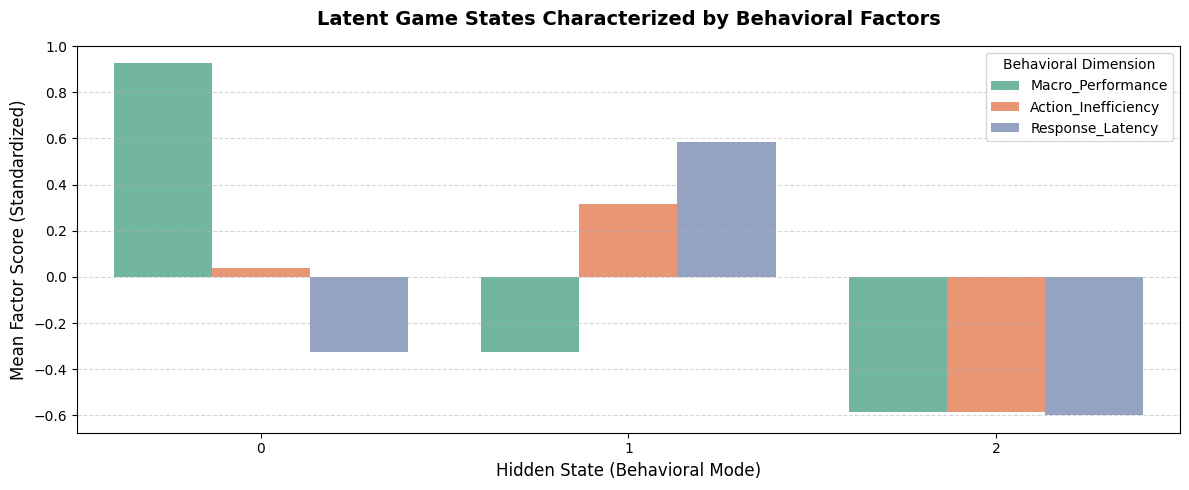

In [14]:
# 4. Visualize the Latent Behavioral States
plt.figure(figsize=(12, 5))

# Melt the dataframe for a tidy barplot format
melted_states = state_means.reset_index().melt(id_vars='Hidden_State',
                                              value_vars=['Macro_Performance', 'Action_Inefficiency', 'Response_Latency'],
                                              var_name='Factor',
                                              value_name='Mean_Factor_Score')

sns.barplot(data=melted_states, x='Hidden_State', y='Mean_Factor_Score', hue='Factor', palette='Set2')
plt.title('Latent Game States Characterized by Behavioral Factors', fontsize=14, weight='bold', pad=15)
plt.xlabel('Hidden State (Behavioral Mode)', fontsize=12)
plt.ylabel('Mean Factor Score (Standardized)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Behavioral Dimension')
plt.tight_layout()
plt.show()


**TO DO: Check this- z score before HMM? State 2 is strange (efficient rotations but everything else going badly) **



- Check outlier rejections- careful about who to reject and make a new drive of just data with outliers removed

- experts vs non experts (high vs low scorers) and break everything down based on these groups